# Financial readiness for AI liability

Quantify Case Competition 2026 · Team Analysts

This notebook recomputes company and line results for 2021–2025. Source money is CAD thousands and is normalized to CAD. It requires an authorized combined organizer workbook; saved outputs are readable without one. See `data/README.md`.

The decision distinction is historical underwriting profitability versus unobserved capital and reinsurance capacity.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
while not (ROOT / "src" / "analysis.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook inside the repository")
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


In [2]:
from src.analysis import load_exhibits, financial_metrics
financial, _ = load_exhibits()
metrics, annual = financial_metrics(financial)
print(f"{len(financial)} line-year records across {financial.line.nunique()} lines")
assert len(financial) == 25
np.testing.assert_allclose(metrics.claim_frequency * metrics.average_severity_cad, metrics.pure_premium_cad)
display(annual.assign(earned_premium_m=annual.earned_premium_cad/1e6,
                      underwriting_profit_m=annual.underwriting_profit_cad/1e6)
        [["year", "earned_premium_m", "underwriting_profit_m", "combined_ratio"]])

25 line-year records across 5 lines


,year,earned_premium_m,underwriting_profit_m,combined_ratio
0,2021,606.4332,104.8819,0.8271
1,2022,582.5165,92.1796,0.8418
2,2023,623.1384,95.5188,0.8467
3,2024,843.3967,131.7034,0.8438
4,2025,834.2218,133.4486,0.8400


## 2025 line comparison

Combined ratio below 100% means underwriting profit before investment income. A high historical margin does not supply an AI technical price.

In [3]:
current = metrics[metrics.year == 2025].copy()
display(current[["line", "loss_ratio", "expense_ratio", "combined_ratio", "underwriting_margin", "underwriting_profit_cad"]])
company = annual[annual.year == 2025].iloc[0]
print(f"2025 combined ratio: {company.combined_ratio:.2%}")
print(f"2025 underwriting profit: CAD {company.underwriting_profit_cad/1e6:,.2f}M")

,line,loss_ratio,expense_ratio,combined_ratio,underwriting_margin,underwriting_profit_cad
4,Errors & Omissions,0.5680,0.2500,0.8180,0.1820,"19,216,000.0000"
9,Cyber Liability,0.6964,0.2800,0.9764,0.0236,"3,121,400.0000"
14,Technology Products Liability,0.5476,0.2500,0.7976,0.2024,"20,389,400.0000"
19,Commercial General Liability,0.5547,0.2200,0.7747,0.2253,"42,131,300.0000"
24,Commercial Auto Liability,0.5927,0.2500,0.8427,0.1573,"48,590,500.0000"


2025 combined ratio: 84.00%
2025 underwriting profit: CAD 133.45M


## Growth is not uniform

Use amounts and a defined period. Aggregate growth is not evidence that every technology-related business expanded. Do not infer an AI cause from these accounting data.

In [4]:
by_line = financial.pivot(index="line", columns="year", values="earned_premium_cad")
change = by_line[2025] - by_line[2021]
print(f"Commercial Auto share of company premium growth, 2021–2025: {change['Commercial Auto Liability']/change.sum():.2%}")
annual_p = annual.set_index("year").earned_premium_cad
print(f"2025 company premium growth: {annual_p.loc[2025]/annual_p.loc[2024]-1:.2%}")
traditional = current[current.line.isin(["Commercial General Liability", "Commercial Auto Liability"])]
print(f"Traditional share of 2025 underwriting profit: {traditional.underwriting_profit_cad.sum()/company.underwriting_profit_cad:.2%}")

Commercial Auto share of company premium growth, 2021–2025: 73.70%
2025 company premium growth: -1.09%
Traditional share of 2025 underwriting profit: 67.98%


## Cyber: unit economics and denominator effects

Frequency changes are percentage points. Severity, pure premium and premium-per-exposure changes are relative growth. Premium per exposure also reflects coverage and business mix.

Frequency change: -16.03 percentage points
average_severity_cad: 82.19%
pure_premium_cad: -41.00%
premium_per_exposure_cad: -50.67%
Loss ratio: 58.22% to 69.64%


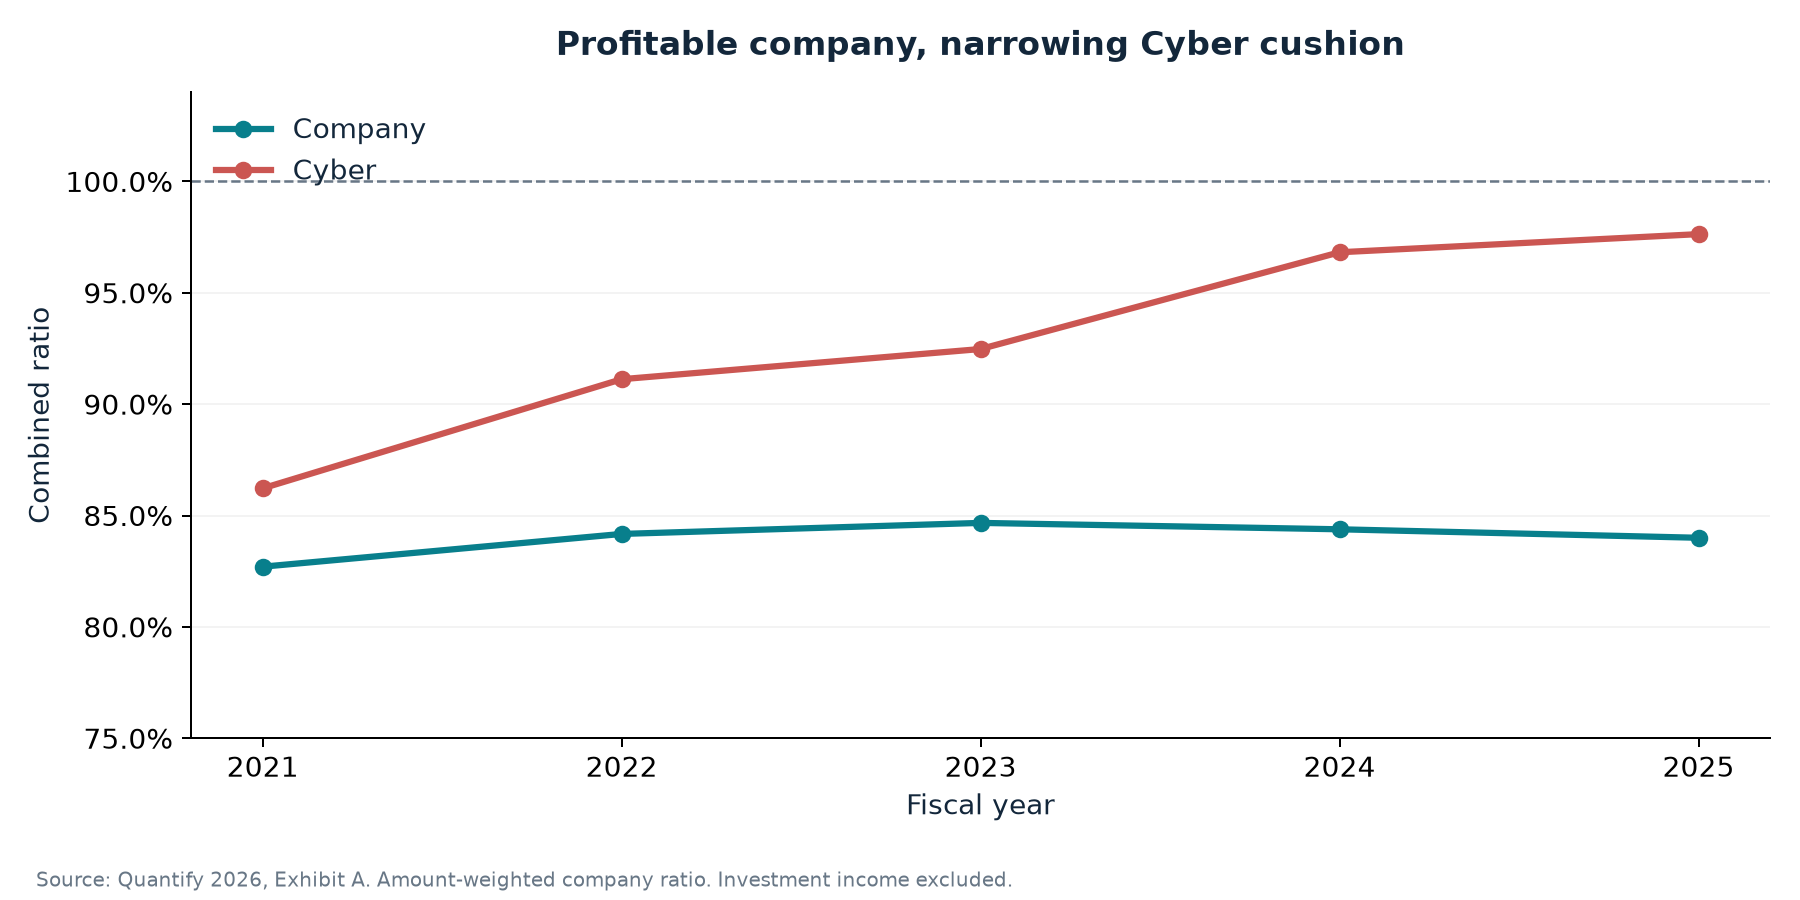

In [5]:
cyber = metrics[metrics.line == "Cyber Liability"].set_index("year")
print(f"Frequency change: {(cyber.loc[2025,'claim_frequency']-cyber.loc[2021,'claim_frequency'])*100:.2f} percentage points")
for field in ["average_severity_cad", "pure_premium_cad", "premium_per_exposure_cad"]:
    print(f"{field}: {cyber.loc[2025,field]/cyber.loc[2021,field]-1:.2%}")
print(f"Loss ratio: {cyber.loc[2021,'loss_ratio']:.2%} to {cyber.loc[2025,'loss_ratio']:.2%}")
display(Image(filename=str(ROOT / "figures/underwriting-performance.png")))

## Decision implication

E&O and Technology Products provide relevant platforms for product assessment. Cyber's remaining margin is thin. None of these observations establishes available capital, reserve adequacy or reinsurance response. A separate AI pilot needs standalone economics and a common-dependency stress assessment.